In [1]:
import numpy as np
%pip install lime
import lime
from tokenizers import Tokenizer
from collections import OrderedDict
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import itertools
from datasets import concatenate_datasets

root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from datasets import load_dataset, concatenate_datasets, DatasetDict

topics = ["stance_abortion", "stance_atheism", "stance_climate", "stance_feminist", "stance_hillary"]

per_topic = [load_dataset("cardiffnlp/tweet_eval", t) for t in topics]

# all topics
dataset = DatasetDict({
    split: concatenate_datasets([ds[split] for ds in per_topic])
    for split in ["train", "validation", "test"]
})
# 1 topic
# dataset = per_topic[0]

dataset = dataset.map(lambda x: {"text": x["text"].replace(" #SemST", "")})
# 1 topic
# dataset = load_dataset("cardiffnlp/tweet_eval", topics[0])

In [3]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

class tfidf(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.dataset = dataset['train']
        self.idf = self._compute_idf()

    def _compute_idf(self) -> 'np.array':
        num_documents = len(self.dataset)
        df = np.zeros(len(self.tokenizer.get_vocab()))

        for example in self.dataset:
            unique_token_ids = set(self.tokenizer.encode(example['text']).ids)
            for token_id in unique_token_ids:
                df[token_id] += 1

        idf = np.log((num_documents + 1) / (df + 1)) + 1
        return idf

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        tf_vector = np.zeros(len(self))
        token_ids = self.tokenizer.encode(x).ids

        for token_id in token_ids:
            tf_vector[token_id] += 1

        if len(token_ids) > 0:
            tf_vector /= len(token_ids)

        tfidf_vector = tf_vector * self.idf
        return tfidf_vector

In [4]:
#tokenizer
vocab_size = 1000
min_frequency = 2
comb_dataset = concatenate_datasets([dataset["train"], dataset["validation"]])
corpus = [text for text in comb_dataset["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [5]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(comb_dataset["text"], comb_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [6]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [7]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [8]:
outcome_space = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [9]:
classifiers = OrderedDict()

In [10]:
token_indicator_encoder = TokenIndicator(tokenizer)
bow_encoder = BagOfWords(tokenizer)
tfidf_encoder = tfidf(tokenizer)

In [11]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [12]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.499 seconds
Dataloader done! Time taken: 0.022 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

/home/richard/Documents/NLP1/Projects/NLP1/Project1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/richard/Documents/NLP1/Projects/NLP1/Project1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 1.0391 | train acc: 0.4693 | val loss: 1.0107 | val acc: 0.4751
Epoch 02 | train loss: 0.9071 | train acc: 0.5465 | val loss: 0.9422 | val acc: 0.5420
Epoch 03 | train loss: 0.7400 | train acc: 0.7177 | val loss: 0.8906 | val acc: 0.5866
Epoch 04 | train loss: 0.5835 | train acc: 0.7979 | val loss: 0.9060 | val acc: 0.5746
Epoch 05 | train loss: 0.4696 | train acc: 0.8464 | val loss: 0.9383 | val acc: 0.5866
Epoch 06 | train loss: 0.3696 | train acc: 0.8919 | val loss: 0.9897 | val acc: 0.5798
Epoch 07 | train loss: 0.2974 | train acc: 0.9262 | val loss: 1.0303 | val acc: 0.5866
Epoch 08 | train loss: 0.2368 | train acc: 0.9558 | val loss: 1.0890 | val acc: 0.5901
Epoch 09 | train loss: 0.1903 | train acc: 0.9687 | val loss: 1.1477 | val acc: 0.5780
Epoch 10 | train loss: 0.1527 | train acc: 0.9837 | val loss: 1.2012 | val acc: 0.5883
Epoch 11 | train loss: 0.1262 | train acc: 0.9897 | val loss: 1.2517 | val acc: 0.5918
Epoch 12 | train loss: 0.1017 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0368 | train acc: 0.4736 | val loss: 1.0074 | val acc: 0.4666
Epoch 02 | train loss: 0.9005 | train acc: 0.5457 | val loss: 0.9314 | val acc: 0.5489
Epoch 03 | train loss: 0.7387 | train acc: 0.7143 | val loss: 0.8637 | val acc: 0.6278
Epoch 04 | train loss: 0.5873 | train acc: 0.8061 | val loss: 0.8449 | val acc: 0.6329
Epoch 05 | train loss: 0.4734 | train acc: 0.8614 | val loss: 0.8614 | val acc: 0.6364
Epoch 06 | train loss: 0.3813 | train acc: 0.8958 | val loss: 0.8816 | val acc: 0.6312
Epoch 07 | train loss: 0.3068 | train acc: 0.9224 | val loss: 0.9103 | val acc: 0.6329
Epoch 08 | train loss: 0.2445 | train acc: 0.9507 | val loss: 0.9542 | val acc: 0.6312
Epoch 09 | train loss: 0.1970 | train acc: 0.9691 | val loss: 1.0064 | val acc: 0.6278
Epoch 10 | train loss: 0.1567 | train acc: 0.9816 | val loss: 1.0263 | val acc: 0.6278
Epoch 11 | train loss: 0.1271 | train acc: 0.9914 | val loss: 1.0823 | val acc: 0.6192
Epoch 12 | train loss: 0.1021 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0432 | train acc: 0.4696 | val loss: 1.0113 | val acc: 0.4708
Epoch 02 | train loss: 0.9154 | train acc: 0.5360 | val loss: 0.9377 | val acc: 0.5326
Epoch 03 | train loss: 0.7549 | train acc: 0.7127 | val loss: 0.8789 | val acc: 0.5928
Epoch 04 | train loss: 0.5977 | train acc: 0.7903 | val loss: 0.8695 | val acc: 0.6168
Epoch 05 | train loss: 0.4810 | train acc: 0.8448 | val loss: 0.8940 | val acc: 0.6065
Epoch 06 | train loss: 0.3861 | train acc: 0.8872 | val loss: 0.9260 | val acc: 0.5997
Epoch 07 | train loss: 0.3089 | train acc: 0.9224 | val loss: 0.9702 | val acc: 0.6031
Epoch 08 | train loss: 0.2475 | train acc: 0.9503 | val loss: 1.0079 | val acc: 0.6048
Epoch 09 | train loss: 0.1976 | train acc: 0.9666 | val loss: 1.0589 | val acc: 0.5997
Epoch 10 | train loss: 0.1588 | train acc: 0.9816 | val loss: 1.1062 | val acc: 0.6117
Epoch 11 | train loss: 0.1290 | train acc: 0.9863 | val loss: 1.1492 | val acc: 0.5979
Epoch 12 | train loss: 0.1056 | train acc: 

In [13]:
classifiers['mlp2_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_indicator-enc/seed-{seed}"
    classifiers['mlp2_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.516 seconds
Dataloader done! Time taken: 0.016 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0466 | train acc: 0.4753 | val loss: 1.0285 | val acc: 0.4751
Epoch 02 | train loss: 0.9050 | train acc: 0.5272 | val loss: 0.9447 | val acc: 0.5403
Epoch 03 | train loss: 0.6102 | train acc: 0.7658 | val loss: 1.0007 | val acc: 0.5901
Epoch 04 | train loss: 0.3542 | train acc: 0.8803 | val loss: 1.1490 | val acc: 0.5695
Epoch 05 | train loss: 0.1781 | train acc: 0.9541 | val loss: 1.3796 | val acc: 0.5746
Epoch 06 | train loss: 0.0818 | train acc: 0.9884 | val loss: 1.6034 | val acc: 0.5626
Epoch 07 | train loss: 0.0368 | train acc: 0.9961 | val loss: 1.8286 | val acc: 0.5609
Epoch 08 | train loss: 0.0220 | train acc: 0.9974 | val loss: 1.9735 | val acc: 0.5489
Epoch 09 | train loss: 0.0175 | train acc: 0.9983 | val loss: 2.0385 | val acc: 0.5626
Epoch 10 | train loss: 0.0102 | train acc: 0.9991 | val loss: 2.1076 | val acc: 0.5557
Epoch 11 | train loss: 0.0077 | train acc: 0.9987 | val loss: 2.1906 | val acc: 0.5626
Epoch 12 | train loss: 0.0065 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0454 | train acc: 0.4728 | val loss: 1.0024 | val acc: 0.5026
Epoch 02 | train loss: 0.8991 | train acc: 0.5388 | val loss: 0.9333 | val acc: 0.5678
Epoch 03 | train loss: 0.6133 | train acc: 0.7512 | val loss: 0.9661 | val acc: 0.5815
Epoch 04 | train loss: 0.3684 | train acc: 0.8790 | val loss: 1.1103 | val acc: 0.5643
Epoch 05 | train loss: 0.1995 | train acc: 0.9472 | val loss: 1.2710 | val acc: 0.5901
Epoch 06 | train loss: 0.0928 | train acc: 0.9841 | val loss: 1.4682 | val acc: 0.5712
Epoch 07 | train loss: 0.0441 | train acc: 0.9966 | val loss: 1.6397 | val acc: 0.5815
Epoch 08 | train loss: 0.0260 | train acc: 0.9974 | val loss: 1.7783 | val acc: 0.5901
Epoch 09 | train loss: 0.0169 | train acc: 0.9979 | val loss: 1.8901 | val acc: 0.5832
Epoch 10 | train loss: 0.0124 | train acc: 0.9991 | val loss: 1.9727 | val acc: 0.5849
Epoch 11 | train loss: 0.0092 | train acc: 0.9987 | val loss: 2.0849 | val acc: 0.5746
Epoch 12 | train loss: 0.0078 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0480 | train acc: 0.4646 | val loss: 1.0271 | val acc: 0.4648
Epoch 02 | train loss: 0.9245 | train acc: 0.5161 | val loss: 0.9205 | val acc: 0.5506
Epoch 03 | train loss: 0.6608 | train acc: 0.7366 | val loss: 0.8843 | val acc: 0.6192
Epoch 04 | train loss: 0.3828 | train acc: 0.8760 | val loss: 0.9907 | val acc: 0.6106
Epoch 05 | train loss: 0.1926 | train acc: 0.9541 | val loss: 1.2005 | val acc: 0.6038
Epoch 06 | train loss: 0.0862 | train acc: 0.9858 | val loss: 1.3889 | val acc: 0.6021
Epoch 07 | train loss: 0.0360 | train acc: 0.9966 | val loss: 1.5308 | val acc: 0.6089
Epoch 08 | train loss: 0.0232 | train acc: 0.9974 | val loss: 1.6471 | val acc: 0.5832
Epoch 09 | train loss: 0.0146 | train acc: 0.9991 | val loss: 1.7361 | val acc: 0.5969
Epoch 10 | train loss: 0.0096 | train acc: 0.9991 | val loss: 1.8213 | val acc: 0.5986
Epoch 11 | train loss: 0.0072 | train acc: 0.9996 | val loss: 1.8880 | val acc: 0.6003
Epoch 12 | train loss: 0.0060 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0477 | train acc: 0.4696 | val loss: 1.0234 | val acc: 0.4691
Epoch 02 | train loss: 0.9190 | train acc: 0.5253 | val loss: 0.9265 | val acc: 0.5361
Epoch 03 | train loss: 0.6367 | train acc: 0.7341 | val loss: 0.9370 | val acc: 0.5825
Epoch 04 | train loss: 0.3646 | train acc: 0.8731 | val loss: 1.0627 | val acc: 0.5790
Epoch 05 | train loss: 0.1849 | train acc: 0.9515 | val loss: 1.2517 | val acc: 0.6014
Epoch 06 | train loss: 0.0819 | train acc: 0.9867 | val loss: 1.4289 | val acc: 0.5979
Epoch 07 | train loss: 0.0380 | train acc: 0.9957 | val loss: 1.6036 | val acc: 0.5928
Epoch 08 | train loss: 0.0248 | train acc: 0.9974 | val loss: 1.7076 | val acc: 0.5893
Epoch 09 | train loss: 0.0168 | train acc: 0.9979 | val loss: 1.8468 | val acc: 0.5893
Epoch 10 | train loss: 0.0106 | train acc: 0.9996 | val loss: 1.9103 | val acc: 0.5962
Epoch 11 | train loss: 0.0078 | train acc: 0.9991 | val loss: 1.9899 | val acc: 0.5859
Epoch 12 | train loss: 0.0067 | train acc: 

In [14]:
classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100}
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [15]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.512 seconds
Dataloader done! Time taken: 0.015 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0426 | train acc: 0.4625 | val loss: 1.0186 | val acc: 0.4786
Epoch 02 | train loss: 0.9064 | train acc: 0.5547 | val loss: 0.9599 | val acc: 0.5232
Epoch 03 | train loss: 0.7387 | train acc: 0.7306 | val loss: 0.9220 | val acc: 0.5746
Epoch 04 | train loss: 0.5821 | train acc: 0.7979 | val loss: 0.9269 | val acc: 0.5883
Epoch 05 | train loss: 0.4652 | train acc: 0.8511 | val loss: 0.9659 | val acc: 0.5798
Epoch 06 | train loss: 0.3697 | train acc: 0.8945 | val loss: 1.0110 | val acc: 0.5729
Epoch 07 | train loss: 0.2961 | train acc: 0.9296 | val loss: 1.0654 | val acc: 0.5763
Epoch 08 | train loss: 0.2348 | train acc: 0.9558 | val loss: 1.1089 | val acc: 0.5712
Epoch 09 | train loss: 0.1855 | train acc: 0.9695 | val loss: 1.1728 | val acc: 0.5712
Epoch 10 | train loss: 0.1488 | train acc: 0.9867 | val loss: 1.2249 | val acc: 0.5763
Epoch 11 | train loss: 0.1195 | train acc: 0.9867 | val loss: 1.2872 | val acc: 0.5678
Epoch 12 | train loss: 0.0958 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0397 | train acc: 0.4702 | val loss: 0.9868 | val acc: 0.5077
Epoch 02 | train loss: 0.8984 | train acc: 0.5663 | val loss: 0.9195 | val acc: 0.5557
Epoch 03 | train loss: 0.7265 | train acc: 0.7332 | val loss: 0.8825 | val acc: 0.6055
Epoch 04 | train loss: 0.5831 | train acc: 0.7945 | val loss: 0.8968 | val acc: 0.5780
Epoch 05 | train loss: 0.4705 | train acc: 0.8451 | val loss: 0.9326 | val acc: 0.5678
Epoch 06 | train loss: 0.3744 | train acc: 0.8975 | val loss: 0.9677 | val acc: 0.5592
Epoch 07 | train loss: 0.3017 | train acc: 0.9249 | val loss: 1.0167 | val acc: 0.5712
Epoch 08 | train loss: 0.2468 | train acc: 0.9468 | val loss: 1.0674 | val acc: 0.5780
Epoch 09 | train loss: 0.1983 | train acc: 0.9665 | val loss: 1.1174 | val acc: 0.5746
Epoch 10 | train loss: 0.1567 | train acc: 0.9798 | val loss: 1.1742 | val acc: 0.5678
Epoch 11 | train loss: 0.1265 | train acc: 0.9871 | val loss: 1.2235 | val acc: 0.5746
Epoch 12 | train loss: 0.1035 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0343 | train acc: 0.4809 | val loss: 1.0110 | val acc: 0.4768
Epoch 02 | train loss: 0.8929 | train acc: 0.5650 | val loss: 0.9330 | val acc: 0.5575
Epoch 03 | train loss: 0.7267 | train acc: 0.7207 | val loss: 0.8814 | val acc: 0.5935
Epoch 04 | train loss: 0.5773 | train acc: 0.8039 | val loss: 0.8826 | val acc: 0.5969
Epoch 05 | train loss: 0.4587 | train acc: 0.8593 | val loss: 0.8859 | val acc: 0.6021
Epoch 06 | train loss: 0.3670 | train acc: 0.8975 | val loss: 0.9227 | val acc: 0.5969
Epoch 07 | train loss: 0.2926 | train acc: 0.9348 | val loss: 0.9686 | val acc: 0.6003
Epoch 08 | train loss: 0.2310 | train acc: 0.9571 | val loss: 1.0155 | val acc: 0.6038
Epoch 09 | train loss: 0.1822 | train acc: 0.9785 | val loss: 1.0511 | val acc: 0.6038
Epoch 10 | train loss: 0.1426 | train acc: 0.9906 | val loss: 1.0988 | val acc: 0.6072
Epoch 11 | train loss: 0.1142 | train acc: 0.9953 | val loss: 1.1382 | val acc: 0.6038
Epoch 12 | train loss: 0.0944 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0377 | train acc: 0.4803 | val loss: 1.0086 | val acc: 0.4691
Epoch 02 | train loss: 0.9013 | train acc: 0.5532 | val loss: 0.9376 | val acc: 0.5395
Epoch 03 | train loss: 0.7395 | train acc: 0.7136 | val loss: 0.8820 | val acc: 0.5790
Epoch 04 | train loss: 0.5899 | train acc: 0.7925 | val loss: 0.8774 | val acc: 0.6048
Epoch 05 | train loss: 0.4662 | train acc: 0.8576 | val loss: 0.8988 | val acc: 0.6117
Epoch 06 | train loss: 0.3780 | train acc: 0.8924 | val loss: 0.9328 | val acc: 0.6168
Epoch 07 | train loss: 0.3011 | train acc: 0.9314 | val loss: 0.9778 | val acc: 0.6203
Epoch 08 | train loss: 0.2423 | train acc: 0.9528 | val loss: 1.0265 | val acc: 0.6151
Epoch 09 | train loss: 0.1882 | train acc: 0.9730 | val loss: 1.0720 | val acc: 0.6168
Epoch 10 | train loss: 0.1554 | train acc: 0.9807 | val loss: 1.1326 | val acc: 0.5962
Epoch 11 | train loss: 0.1199 | train acc: 0.9884 | val loss: 1.1745 | val acc: 0.6100
Epoch 12 | train loss: 0.1004 | train acc: 

In [16]:
classifiers['mlp2_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_bow-enc/seed-{seed}"
    classifiers['mlp2_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.780 seconds
Dataloader done! Time taken: 0.020 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0458 | train acc: 0.4607 | val loss: 1.0289 | val acc: 0.4751
Epoch 02 | train loss: 0.9264 | train acc: 0.5174 | val loss: 0.9398 | val acc: 0.5352
Epoch 03 | train loss: 0.6840 | train acc: 0.7242 | val loss: 0.9876 | val acc: 0.5660
Epoch 04 | train loss: 0.4038 | train acc: 0.8593 | val loss: 1.1707 | val acc: 0.5386
Epoch 05 | train loss: 0.2088 | train acc: 0.9374 | val loss: 1.3629 | val acc: 0.5557
Epoch 06 | train loss: 0.0978 | train acc: 0.9798 | val loss: 1.6245 | val acc: 0.5695
Epoch 07 | train loss: 0.0425 | train acc: 0.9979 | val loss: 1.7569 | val acc: 0.5643
Epoch 08 | train loss: 0.0267 | train acc: 0.9966 | val loss: 1.9027 | val acc: 0.5678
Epoch 09 | train loss: 0.0163 | train acc: 0.9996 | val loss: 2.0381 | val acc: 0.5695
Epoch 10 | train loss: 0.0115 | train acc: 0.9991 | val loss: 2.1432 | val acc: 0.5626
Epoch 11 | train loss: 0.0100 | train acc: 0.9991 | val loss: 2.2054 | val acc: 0.5592
Epoch 12 | train loss: 0.0089 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0455 | train acc: 0.4706 | val loss: 0.9951 | val acc: 0.5026
Epoch 02 | train loss: 0.8977 | train acc: 0.5659 | val loss: 0.9127 | val acc: 0.5746
Epoch 03 | train loss: 0.6114 | train acc: 0.7662 | val loss: 0.9650 | val acc: 0.5643
Epoch 04 | train loss: 0.3477 | train acc: 0.8786 | val loss: 1.1174 | val acc: 0.5557
Epoch 05 | train loss: 0.1772 | train acc: 0.9532 | val loss: 1.2730 | val acc: 0.5523
Epoch 06 | train loss: 0.0761 | train acc: 0.9884 | val loss: 1.4961 | val acc: 0.5592
Epoch 07 | train loss: 0.0370 | train acc: 0.9979 | val loss: 1.6193 | val acc: 0.5729
Epoch 08 | train loss: 0.0229 | train acc: 0.9987 | val loss: 1.7732 | val acc: 0.5643
Epoch 09 | train loss: 0.0166 | train acc: 0.9991 | val loss: 1.8751 | val acc: 0.5695
Epoch 10 | train loss: 0.0153 | train acc: 0.9987 | val loss: 1.9381 | val acc: 0.5729
Epoch 11 | train loss: 0.0089 | train acc: 0.9991 | val loss: 2.0232 | val acc: 0.5695
Epoch 12 | train loss: 0.0110 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0469 | train acc: 0.4595 | val loss: 1.0304 | val acc: 0.4666
Epoch 02 | train loss: 0.9154 | train acc: 0.5281 | val loss: 0.9447 | val acc: 0.5643
Epoch 03 | train loss: 0.6601 | train acc: 0.7344 | val loss: 0.9329 | val acc: 0.5815
Epoch 04 | train loss: 0.3909 | train acc: 0.8644 | val loss: 1.0135 | val acc: 0.5763
Epoch 05 | train loss: 0.2023 | train acc: 0.9481 | val loss: 1.2108 | val acc: 0.6021
Epoch 06 | train loss: 0.0900 | train acc: 0.9871 | val loss: 1.3839 | val acc: 0.5986
Epoch 07 | train loss: 0.0413 | train acc: 0.9970 | val loss: 1.5127 | val acc: 0.6038
Epoch 08 | train loss: 0.0216 | train acc: 0.9974 | val loss: 1.6569 | val acc: 0.6003
Epoch 09 | train loss: 0.0142 | train acc: 0.9987 | val loss: 1.7926 | val acc: 0.6003
Epoch 10 | train loss: 0.0103 | train acc: 0.9996 | val loss: 1.8398 | val acc: 0.6072
Epoch 11 | train loss: 0.0075 | train acc: 0.9991 | val loss: 1.9677 | val acc: 0.6038
Epoch 12 | train loss: 0.0060 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0497 | train acc: 0.4726 | val loss: 1.0228 | val acc: 0.4691
Epoch 02 | train loss: 0.9219 | train acc: 0.5060 | val loss: 0.9261 | val acc: 0.5361
Epoch 03 | train loss: 0.6573 | train acc: 0.7380 | val loss: 0.9029 | val acc: 0.5893
Epoch 04 | train loss: 0.3866 | train acc: 0.8726 | val loss: 1.0350 | val acc: 0.6117
Epoch 05 | train loss: 0.2025 | train acc: 0.9503 | val loss: 1.2081 | val acc: 0.5945
Epoch 06 | train loss: 0.0924 | train acc: 0.9863 | val loss: 1.4084 | val acc: 0.5911
Epoch 07 | train loss: 0.0431 | train acc: 0.9961 | val loss: 1.5870 | val acc: 0.5876
Epoch 08 | train loss: 0.0232 | train acc: 0.9987 | val loss: 1.7049 | val acc: 0.6014
Epoch 09 | train loss: 0.0161 | train acc: 0.9987 | val loss: 1.8017 | val acc: 0.6082
Epoch 10 | train loss: 0.0146 | train acc: 0.9987 | val loss: 1.9255 | val acc: 0.6031
Epoch 11 | train loss: 0.0093 | train acc: 0.9996 | val loss: 1.9784 | val acc: 0.6031
Epoch 12 | train loss: 0.0079 | train acc: 

In [17]:
classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    classifiers['logistic_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=tfidf_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, catego

In [18]:
classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    classifiers['mlp_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=tfidf(tokenizer),
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.625 seconds
Dataloader done! Time taken: 0.017 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0650 | train acc: 0.4796 | val loss: 1.0480 | val acc: 0.4751
Epoch 02 | train loss: 1.0212 | train acc: 0.4796 | val loss: 1.0246 | val acc: 0.4751
Epoch 03 | train loss: 0.9662 | train acc: 0.4865 | val loss: 0.9849 | val acc: 0.4871
Epoch 04 | train loss: 0.8751 | train acc: 0.5873 | val loss: 0.9324 | val acc: 0.5506
Epoch 05 | train loss: 0.7692 | train acc: 0.7139 | val loss: 0.8989 | val acc: 0.5969
Epoch 06 | train loss: 0.6825 | train acc: 0.7602 | val loss: 0.8885 | val acc: 0.5780
Epoch 07 | train loss: 0.6108 | train acc: 0.7834 | val loss: 0.8921 | val acc: 0.5901
Epoch 08 | train loss: 0.5591 | train acc: 0.8035 | val loss: 0.9093 | val acc: 0.5832
Epoch 09 | train loss: 0.5163 | train acc: 0.8134 | val loss: 0.9229 | val acc: 0.5883
Epoch 10 | train loss: 0.4794 | train acc: 0.8310 | val loss: 0.9375 | val acc: 0.5866
Epoch 11 | train loss: 0.4470 | train acc: 0.8464 | val loss: 0.9640 | val acc: 0.5832
Epoch 12 | train loss: 0.4233 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0785 | train acc: 0.4144 | val loss: 1.0348 | val acc: 0.5026
Epoch 02 | train loss: 1.0238 | train acc: 0.4728 | val loss: 1.0019 | val acc: 0.5026
Epoch 03 | train loss: 0.9718 | train acc: 0.4796 | val loss: 0.9622 | val acc: 0.5077
Epoch 04 | train loss: 0.8897 | train acc: 0.5568 | val loss: 0.9172 | val acc: 0.5849
Epoch 05 | train loss: 0.7896 | train acc: 0.7083 | val loss: 0.8804 | val acc: 0.5832
Epoch 06 | train loss: 0.6993 | train acc: 0.7538 | val loss: 0.8661 | val acc: 0.5986
Epoch 07 | train loss: 0.6285 | train acc: 0.7799 | val loss: 0.8706 | val acc: 0.5798
Epoch 08 | train loss: 0.5724 | train acc: 0.7992 | val loss: 0.8804 | val acc: 0.5832
Epoch 09 | train loss: 0.5317 | train acc: 0.8087 | val loss: 0.9009 | val acc: 0.5780
Epoch 10 | train loss: 0.4916 | train acc: 0.8280 | val loss: 0.9226 | val acc: 0.5798
Epoch 11 | train loss: 0.4611 | train acc: 0.8417 | val loss: 0.9536 | val acc: 0.5712
Epoch 12 | train loss: 0.4330 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0647 | train acc: 0.4822 | val loss: 1.0505 | val acc: 0.4648
Epoch 02 | train loss: 1.0155 | train acc: 0.4822 | val loss: 1.0266 | val acc: 0.4648
Epoch 03 | train loss: 0.9605 | train acc: 0.4891 | val loss: 0.9851 | val acc: 0.4768
Epoch 04 | train loss: 0.8747 | train acc: 0.5749 | val loss: 0.9319 | val acc: 0.5712
Epoch 05 | train loss: 0.7779 | train acc: 0.7061 | val loss: 0.9044 | val acc: 0.5798
Epoch 06 | train loss: 0.6942 | train acc: 0.7503 | val loss: 0.8762 | val acc: 0.6038
Epoch 07 | train loss: 0.6285 | train acc: 0.7812 | val loss: 0.8740 | val acc: 0.5935
Epoch 08 | train loss: 0.5757 | train acc: 0.7945 | val loss: 0.8823 | val acc: 0.5952
Epoch 09 | train loss: 0.5331 | train acc: 0.8138 | val loss: 0.8888 | val acc: 0.5866
Epoch 10 | train loss: 0.4976 | train acc: 0.8228 | val loss: 0.8983 | val acc: 0.6003
Epoch 11 | train loss: 0.4660 | train acc: 0.8387 | val loss: 0.9173 | val acc: 0.6003
Epoch 12 | train loss: 0.4383 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0798 | train acc: 0.3945 | val loss: 1.0504 | val acc: 0.4691
Epoch 02 | train loss: 1.0175 | train acc: 0.4811 | val loss: 1.0244 | val acc: 0.4691
Epoch 03 | train loss: 0.9621 | train acc: 0.4850 | val loss: 0.9848 | val acc: 0.4811
Epoch 04 | train loss: 0.8772 | train acc: 0.5686 | val loss: 0.9377 | val acc: 0.5584
Epoch 05 | train loss: 0.7794 | train acc: 0.6947 | val loss: 0.9037 | val acc: 0.5808
Epoch 06 | train loss: 0.6903 | train acc: 0.7466 | val loss: 0.8881 | val acc: 0.5859
Epoch 07 | train loss: 0.6226 | train acc: 0.7766 | val loss: 0.8899 | val acc: 0.5859
Epoch 08 | train loss: 0.5679 | train acc: 0.8032 | val loss: 0.9028 | val acc: 0.5859
Epoch 09 | train loss: 0.5251 | train acc: 0.8096 | val loss: 0.9134 | val acc: 0.5911
Epoch 10 | train loss: 0.4877 | train acc: 0.8302 | val loss: 0.9348 | val acc: 0.5945
Epoch 11 | train loss: 0.4567 | train acc: 0.8401 | val loss: 0.9578 | val acc: 0.5808
Epoch 12 | train loss: 0.4299 | train acc: 

In [19]:
classifiers['mlp2_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_tfidf-enc/seed-{seed}"
    classifiers['mlp2_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.631 seconds
Dataloader done! Time taken: 0.018 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0412 | train acc: 0.4758 | val loss: 1.0270 | val acc: 0.4751
Epoch 02 | train loss: 0.8996 | train acc: 0.5495 | val loss: 0.9327 | val acc: 0.5540
Epoch 03 | train loss: 0.6262 | train acc: 0.7640 | val loss: 0.9804 | val acc: 0.5592
Epoch 04 | train loss: 0.3657 | train acc: 0.8769 | val loss: 1.1370 | val acc: 0.5763
Epoch 05 | train loss: 0.1824 | train acc: 0.9524 | val loss: 1.3450 | val acc: 0.5540
Epoch 06 | train loss: 0.0859 | train acc: 0.9863 | val loss: 1.5973 | val acc: 0.5643
Epoch 07 | train loss: 0.0403 | train acc: 0.9953 | val loss: 1.7843 | val acc: 0.5575
Epoch 08 | train loss: 0.0239 | train acc: 0.9987 | val loss: 1.9313 | val acc: 0.5746
Epoch 09 | train loss: 0.0209 | train acc: 0.9970 | val loss: 2.0585 | val acc: 0.5678
Epoch 10 | train loss: 0.0124 | train acc: 0.9987 | val loss: 2.1586 | val acc: 0.5643
Epoch 11 | train loss: 0.0106 | train acc: 0.9983 | val loss: 2.2264 | val acc: 0.5678
Epoch 12 | train loss: 0.0096 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0472 | train acc: 0.4710 | val loss: 1.0057 | val acc: 0.5026
Epoch 02 | train loss: 0.9128 | train acc: 0.5294 | val loss: 0.9005 | val acc: 0.5678
Epoch 03 | train loss: 0.6221 | train acc: 0.7555 | val loss: 0.9318 | val acc: 0.5935
Epoch 04 | train loss: 0.3650 | train acc: 0.8760 | val loss: 1.0961 | val acc: 0.5780
Epoch 05 | train loss: 0.1895 | train acc: 0.9502 | val loss: 1.2834 | val acc: 0.5729
Epoch 06 | train loss: 0.0857 | train acc: 0.9888 | val loss: 1.4959 | val acc: 0.5815
Epoch 07 | train loss: 0.0439 | train acc: 0.9957 | val loss: 1.6744 | val acc: 0.5695
Epoch 08 | train loss: 0.0287 | train acc: 0.9966 | val loss: 1.8223 | val acc: 0.5798
Epoch 09 | train loss: 0.0169 | train acc: 0.9983 | val loss: 1.9392 | val acc: 0.5712
Epoch 10 | train loss: 0.0143 | train acc: 0.9979 | val loss: 2.0088 | val acc: 0.5643
Epoch 11 | train loss: 0.0102 | train acc: 0.9983 | val loss: 2.1115 | val acc: 0.5712
Epoch 12 | train loss: 0.0100 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0447 | train acc: 0.4801 | val loss: 1.0262 | val acc: 0.4648
Epoch 02 | train loss: 0.9132 | train acc: 0.5230 | val loss: 0.9359 | val acc: 0.5660
Epoch 03 | train loss: 0.6449 | train acc: 0.7332 | val loss: 0.9297 | val acc: 0.5986
Epoch 04 | train loss: 0.3732 | train acc: 0.8756 | val loss: 1.0671 | val acc: 0.5952
Epoch 05 | train loss: 0.1818 | train acc: 0.9511 | val loss: 1.1904 | val acc: 0.5832
Epoch 06 | train loss: 0.0811 | train acc: 0.9863 | val loss: 1.3563 | val acc: 0.5832
Epoch 07 | train loss: 0.0363 | train acc: 0.9970 | val loss: 1.5365 | val acc: 0.5935
Epoch 08 | train loss: 0.0226 | train acc: 0.9983 | val loss: 1.6432 | val acc: 0.5986
Epoch 09 | train loss: 0.0154 | train acc: 0.9979 | val loss: 1.7166 | val acc: 0.5952
Epoch 10 | train loss: 0.0097 | train acc: 0.9996 | val loss: 1.8261 | val acc: 0.6003
Epoch 11 | train loss: 0.0076 | train acc: 0.9991 | val loss: 1.9232 | val acc: 0.5952
Epoch 12 | train loss: 0.0055 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0492 | train acc: 0.4794 | val loss: 1.0299 | val acc: 0.4691
Epoch 02 | train loss: 0.9300 | train acc: 0.5274 | val loss: 0.9278 | val acc: 0.5430
Epoch 03 | train loss: 0.6753 | train acc: 0.7226 | val loss: 0.9273 | val acc: 0.5842
Epoch 04 | train loss: 0.4145 | train acc: 0.8499 | val loss: 1.0254 | val acc: 0.5876
Epoch 05 | train loss: 0.2254 | train acc: 0.9344 | val loss: 1.1939 | val acc: 0.5979
Epoch 06 | train loss: 0.1061 | train acc: 0.9824 | val loss: 1.3822 | val acc: 0.5962
Epoch 07 | train loss: 0.0516 | train acc: 0.9919 | val loss: 1.5178 | val acc: 0.5911
Epoch 08 | train loss: 0.0294 | train acc: 0.9961 | val loss: 1.6538 | val acc: 0.5979
Epoch 09 | train loss: 0.0200 | train acc: 0.9983 | val loss: 1.7921 | val acc: 0.5876
Epoch 10 | train loss: 0.0133 | train acc: 0.9987 | val loss: 1.8798 | val acc: 0.5876
Epoch 11 | train loss: 0.0092 | train acc: 0.9991 | val loss: 1.9480 | val acc: 0.5876
Epoch 12 | train loss: 0.0076 | train acc: 

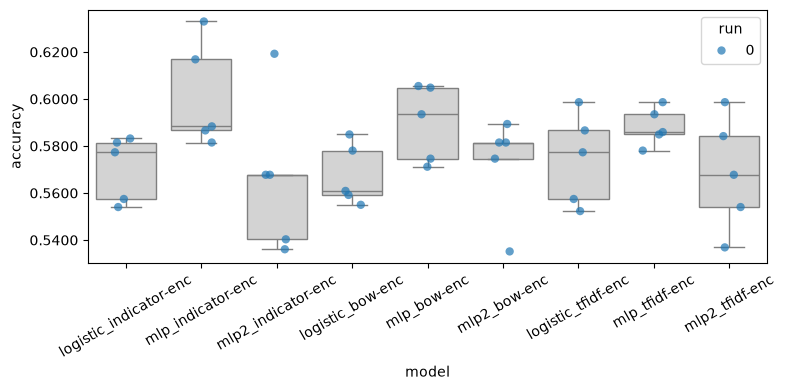

In [20]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))

In [21]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])


A = logistic_indicator-enc, B = mlp_indicator-enc
P(A wins) = 0.0279
P(Tie)    = 0.0358
P(B wins) = 0.9363
Effect Size = 2.29

A = logistic_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.4904
P(Tie)    = 0.1754
P(B wins) = 0.3342
Effect Size = -0.22

A = mlp_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.9019
P(Tie)    = 0.0442
P(B wins) = 0.0539
Effect Size = -1.81


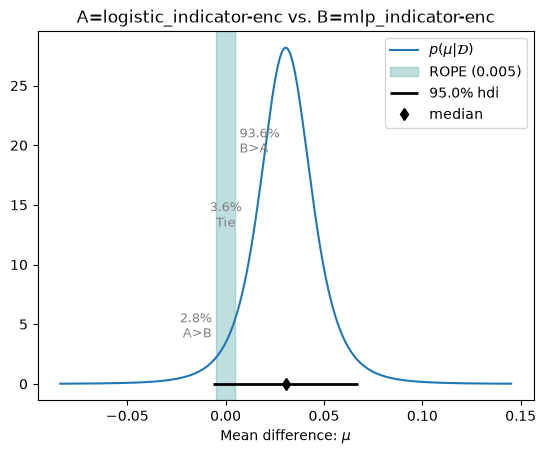

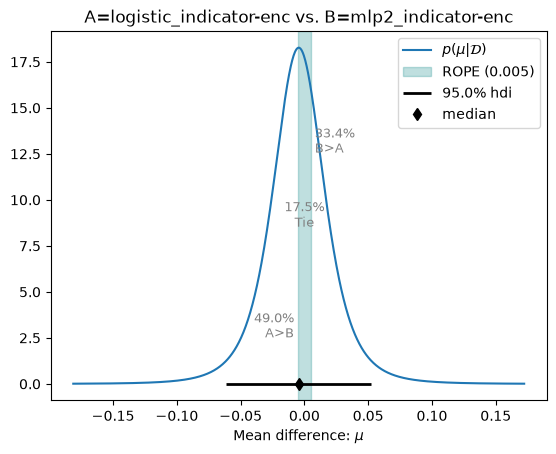

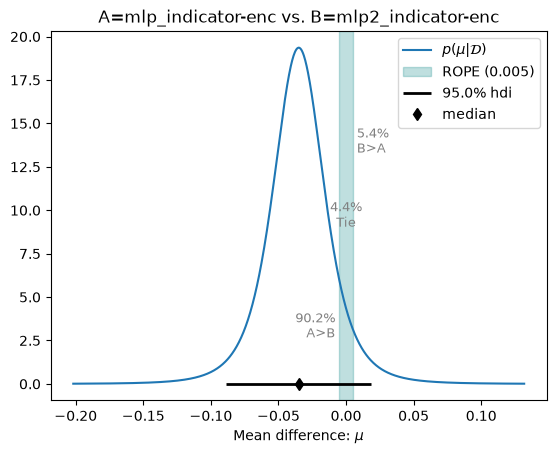

In [22]:
models = {
    "logistic_indicator-enc": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "mlp_indicator-enc": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "mlp2_indicator-enc": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

rope = 0.005

# Compare every pair of models
for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(rope)

    print(f"\nA = {name_a}, B = {name_b}")
    print(f"P(A wins) = {p_a:.4f}")
    print(f"P(Tie)    = {p_tie:.4f}")
    print(f"P(B wins) = {p_b:.4f}")
    print(f"Effect Size = {posterior.effect_size:.2f}")

    _ = posterior.plot(rope)

In [23]:

from pathlib import Path
import Project1.smlp as smlp
import Project1.smlp2 as smlp2

# Find saved checkpoints from your cross-validation
def find_checkpoints(model_name):
    folder = results_folder / model_name / "seed-0"

    checkpoints = sorted(
        path.with_suffix("")
        for path in folder.rglob("*.pt")
        if path.with_suffix(".json").exists()
    )

    if not checkpoints:
        raise FileNotFoundError(
            f"No saved model checkpoints found in {folder}"
        )

    return checkpoints


mlp_checkpoints = find_checkpoints("mlp_indicator-enc")
mlp2_checkpoints = find_checkpoints("mlp2_indicator-enc")

print("Original MLP checkpoints:")
for i, path in enumerate(mlp_checkpoints):
    print(i, path)

print("\nModified MLP checkpoints:")
for i, path in enumerate(mlp2_checkpoints):
    print(i, path)


Original MLP checkpoints:
0 results/mlp_indicator-enc/seed-0/fold-0/model
1 results/mlp_indicator-enc/seed-0/fold-1/model
2 results/mlp_indicator-enc/seed-0/fold-2/model
3 results/mlp_indicator-enc/seed-0/fold-3/model
4 results/mlp_indicator-enc/seed-0/fold-4/model

Modified MLP checkpoints:
0 results/mlp2_indicator-enc/seed-0/fold-0/model
1 results/mlp2_indicator-enc/seed-0/fold-1/model
2 results/mlp2_indicator-enc/seed-0/fold-2/model
3 results/mlp2_indicator-enc/seed-0/fold-3/model
4 results/mlp2_indicator-enc/seed-0/fold-4/model


In [24]:
# Select corresponding checkpoints from the same fold
fold = 0

mlp_model = smlp.load(
    str(mlp_checkpoints[fold]),
    device="cpu"
)

mlp2_model = smlp2.load2(
    str(mlp2_checkpoints[fold]),
    device="cpu"
)

mlp_model.eval()
mlp2_model.eval()

print("Both MLP models loaded successfully!")

Both MLP models loaded successfully!


In [ ]:
# Log-linear
def logistic_predict(texts, encoder):
    return Project1.loglin.predict_probs(
        texts,
        logistic_model,
        encoder
    )

for i, path in enumerate(mlp2_checkpoints):
    print(i, path)

# Original MLP
def mlp_predict(texts, encoder):
    return Project1.smlp.predict_probs(
        texts,
        mlp_model,
        encoder
    )

# Modified MLP (two hidden layers)
def mlp2_predict(texts, encoder):
    return Project1.smlp2.predict_probs2(
        texts,
        mlp2_model,
        encoder
    )

encoders = {token_indicator_encoder, bow_encoder, tfidf_encoder}

# Models for LIME
models = {
    "Log-linear": logistic_predict,
    "Original MLP": mlp_predict,
    "Modified MLP": mlp2_predict
}

In [27]:
tweet_id = 157
test_text = dataset["test"][tweet_id]
print(test_text)
print("Original MLP:", mlp_predict(test_text, token_indicator_encoder))
print("Modified MLP:", mlp2_predict(test_text, token_indicator_encoder))
print("Log-linear:", logistic_predict(test_text, token_indicator_encoder))

{'text': 'What about in cases of rape', 'label': 2}
Original MLP: [[0.3422671  0.32477856 0.3329543 ]
 [0.2746566  0.36790925 0.35743412]]
Modified MLP: [[0.33737817 0.34310493 0.31951693]
 [0.2785341  0.3681503  0.3533156 ]]
Log-linear: [[0.47567861 0.26924195 0.25507943]
 [0.28488149 0.2171727  0.49794581]]



Tweet 1: Where is the childcare program @user which you said would be in place? #loneparents #7istooyoung
True class: against

--- Log-linear ---
Prediction: against
Probabilities: [0.295  0.5868 0.1183]
Explanation: [(np.str_('7istooyoung'), 0.3023266987087352), (np.str_('loneparents'), 0.29652999172702643), (np.str_('place'), -0.24158204563797417), (np.str_('user'), -0.19113127603664212), (np.str_('would'), -0.15479506595782944), (np.str_('childcare'), 0.1317081408676334), (np.str_('be'), 0.08921216595029959), (np.str_('program'), -0.08809893849197177), (np.str_('in'), 0.0628313048589118), (np.str_('Where'), -0.05471914363057895)]


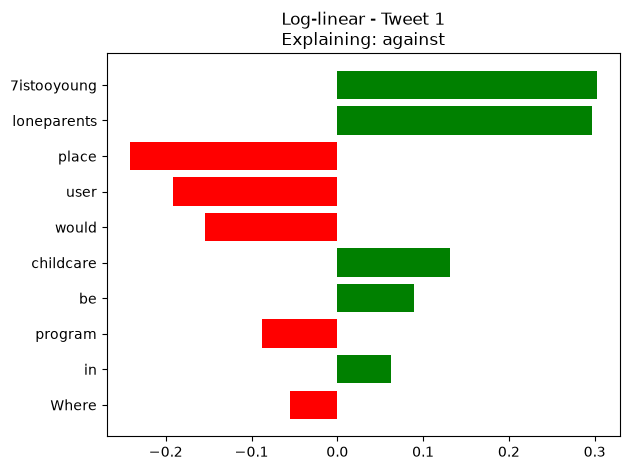


--- Original MLP ---
Prediction: against
Probabilities: [0.3372 0.5288 0.134 ]
Explanation: [(np.str_('loneparents'), 0.13015617606526173), (np.str_('7istooyoung'), 0.09582681682241793), (np.str_('place'), -0.0932200702947736), (np.str_('user'), -0.06277873690429432), (np.str_('the'), 0.051490735745692), (np.str_('be'), 0.030510140690944328), (np.str_('said'), 0.02801761875036472), (np.str_('program'), -0.026945812718197727), (np.str_('childcare'), 0.025747498217280226), (np.str_('which'), -0.01916683141504028)]


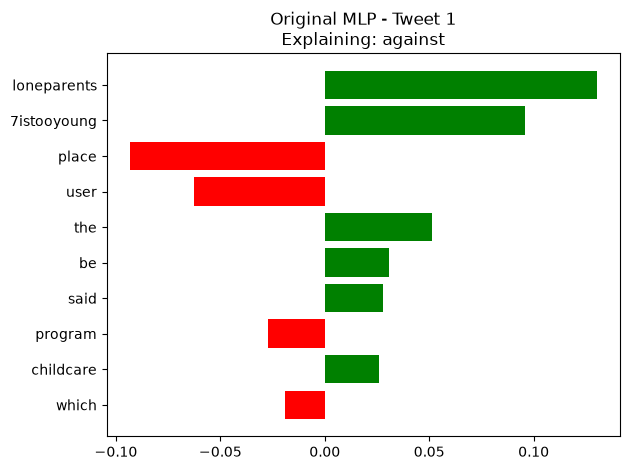


--- Modified MLP ---
Prediction: against
Probabilities: [0.2679 0.4941 0.238 ]
Explanation: [(np.str_('loneparents'), 0.08701483546515323), (np.str_('the'), 0.052036315019957605), (np.str_('7istooyoung'), 0.04910878409572761), (np.str_('Where'), -0.04367667725116346), (np.str_('user'), -0.040366907037405954), (np.str_('be'), 0.03522186239096013), (np.str_('childcare'), 0.033801424526930336), (np.str_('which'), -0.03193309470380403), (np.str_('place'), -0.022859429986886084), (np.str_('program'), -0.0179689177407235)]


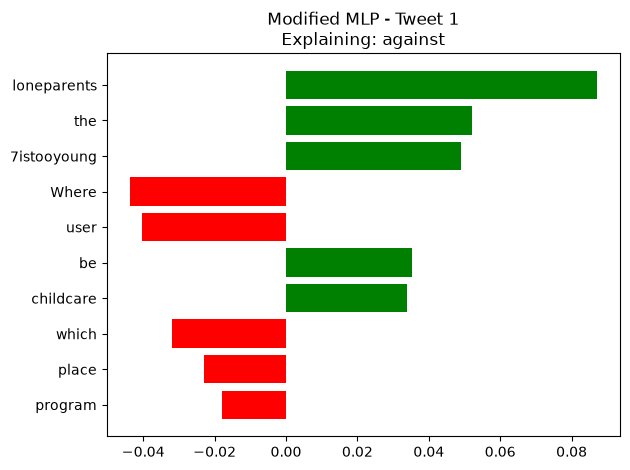


Tweet 8: Pray for the Navy yard. God please keep the casualties minimal.   #1A #2A #NRA #COS #CCOT #TGDN #PJNET  #WAKEUPAMERICA
True class: against

--- Log-linear ---
Prediction: against
Probabilities: [0.0049 0.9951 0.    ]
Explanation: [(np.str_('God'), 0.1430764747110747), (np.str_('please'), 0.11690383078022522), (np.str_('NRA'), 0.0521416787605129), (np.str_('TGDN'), -0.04986128830842693), (np.str_('casualties'), 0.048695129784865294), (np.str_('yard'), -0.04013077747332337), (np.str_('CCOT'), 0.033439420246339994), (np.str_('PJNET'), -0.019839048166905713), (np.str_('2A'), 0.018258330474477544), (np.str_('1A'), -0.015219141444824365)]


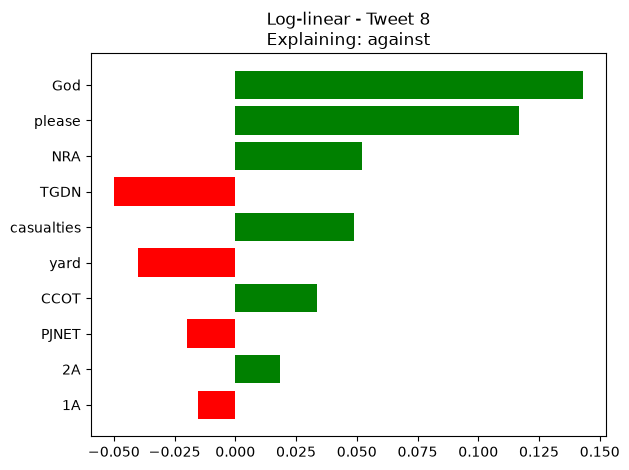


--- Original MLP ---
Prediction: against
Probabilities: [0.233  0.7477 0.0194]
Explanation: [(np.str_('God'), 0.14441459522417516), (np.str_('please'), 0.11254228041170435), (np.str_('yard'), -0.07693633839541748), (np.str_('casualties'), 0.07362589994927818), (np.str_('WAKEUPAMERICA'), -0.06826370520432262), (np.str_('TGDN'), -0.05205556607864331), (np.str_('the'), 0.049323511678782656), (np.str_('PJNET'), 0.04279955515704964), (np.str_('CCOT'), 0.04102530729763489), (np.str_('1A'), -0.023347684013622808)]


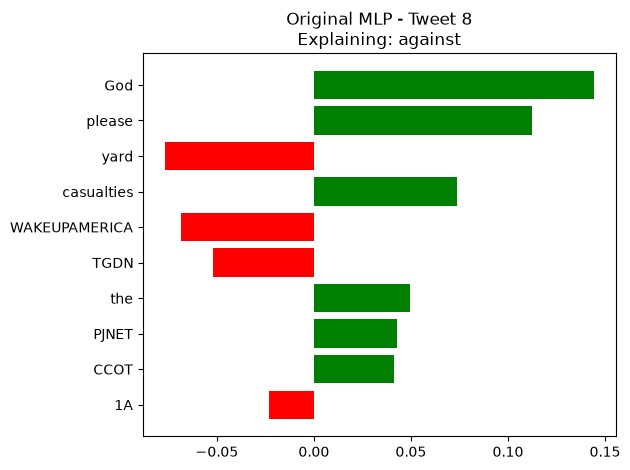


--- Modified MLP ---
Prediction: against
Probabilities: [0.2518 0.7064 0.0419]
Explanation: [(np.str_('God'), 0.10335965041526768), (np.str_('please'), 0.08348979285248445), (np.str_('casualties'), 0.05908164600089606), (np.str_('WAKEUPAMERICA'), -0.051613632870221124), (np.str_('the'), 0.04917156276690112), (np.str_('1A'), -0.03230474764284965), (np.str_('Navy'), -0.0314407501537668), (np.str_('TGDN'), -0.031107129957561423), (np.str_('CCOT'), 0.02822729487311377), (np.str_('yard'), -0.025803187993130396)]


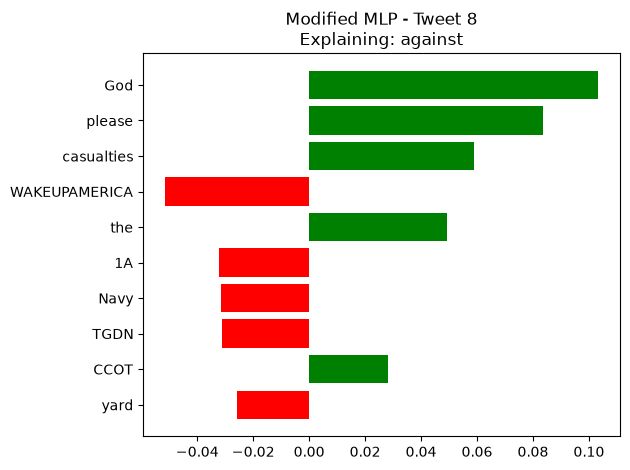


Tweet 157: What about in cases of rape
True class: favor

--- Log-linear ---
Prediction: favor
Probabilities: [0.2626 0.1581 0.5793]
Explanation: [(np.str_('What'), 0.1980881193549047), (np.str_('cases'), 0.174720331724919), (np.str_('about'), -0.09892664268811788), (np.str_('in'), 0.04826779472286172), (np.str_('of'), -0.04634021606416487), (np.str_('rape'), 0.01966837370327301)]


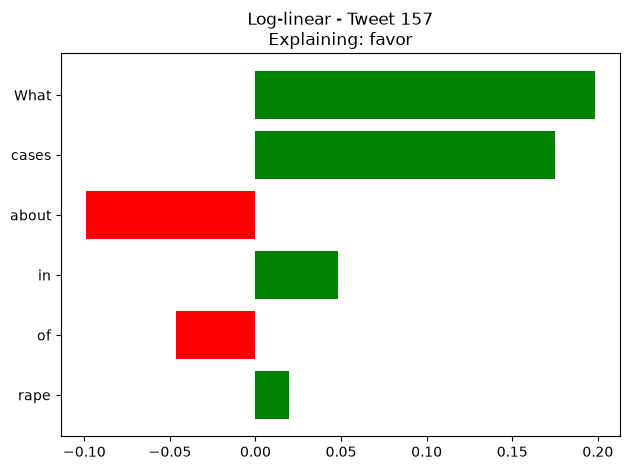


--- Original MLP ---
Prediction: favor
Probabilities: [0.2868 0.3505 0.3628]
Explanation: [(np.str_('cases'), 0.056342734334795634), (np.str_('of'), -0.04199551765636463), (np.str_('What'), 0.02076834904127244), (np.str_('rape'), -0.013044651511576808), (np.str_('about'), 0.0014599421727077575), (np.str_('in'), 3.1405672917543595e-05)]


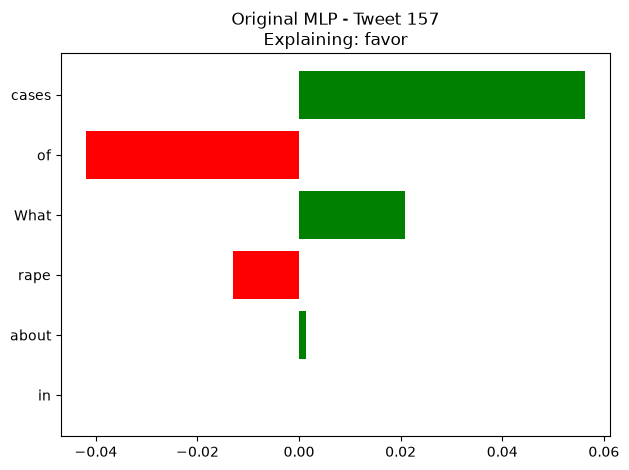


--- Modified MLP ---
Prediction: against
Probabilities: [0.3082 0.3524 0.3393]
Explanation: [(np.str_('cases'), 0.06271599518425423), (np.str_('of'), -0.02737011595568284), (np.str_('rape'), -0.010979121959124288), (np.str_('in'), 0.002131250993081698), (np.str_('about'), -0.0012033113554918338), (np.str_('What'), 1.709139725824458e-05)]


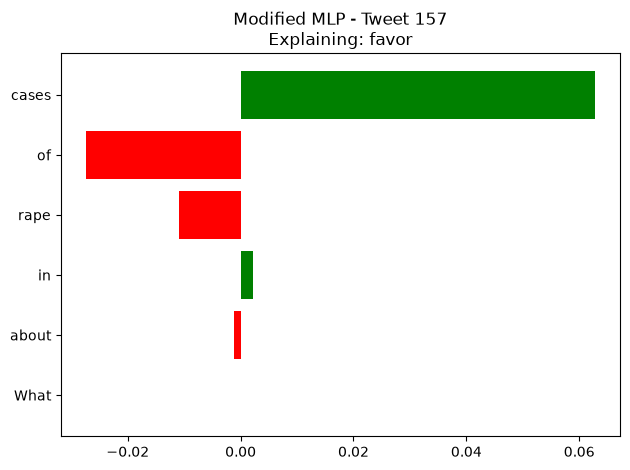

In [34]:
from lime.lime_text import LimeTextExplainer
import numpy as np
import matplotlib.pyplot as plt
from functools import partial

class_names = dataset["train"].features["label"].names

explainer = LimeTextExplainer(
    class_names=class_names,
    random_state=42
)

models = {
    "Log-linear": partial(logistic_predict, encoder=token_indicator_encoder),
    "Original MLP": partial(mlp_predict, encoder=token_indicator_encoder),
    "Modified MLP": partial(mlp2_predict, encoder=token_indicator_encoder)
}

tweets = [1, 8, 157]

for tweet_id in tweets:

    example = dataset["test"][tweet_id]

    text = example["text"]
    true_label = int(example["label"])

    print(f"\n{'=' * 60}")
    print(f"Tweet {tweet_id}: {text}")
    print(f"True class: {class_names[true_label]}")

    for model_name, predict_fn in models.items():

        probabilities = predict_fn([text], encoder=token_indicator_encoder)[0]
        predicted_label = int(np.argmax(probabilities))

        # Explain the same target class across all models
        exp = explainer.explain_instance(
            text,
            predict_fn,
            num_features=10,
            num_samples=1000,
            labels=(true_label,)
        )

        print(f"\n--- {model_name} ---")
        print("Prediction:", class_names[predicted_label])
        print("Probabilities:", probabilities.round(4))
        print("Explanation:", exp.as_list(label=true_label))

        fig = exp.as_pyplot_figure(label=true_label)
        plt.title(
            f"{model_name} - Tweet {tweet_id}\n"
            f"Explaining: {class_names[true_label]}"
        )
        plt.tight_layout()
        plt.show()


In [35]:
# Collect cross-validation accuracy measurements
model_scores = {
    "Log-linear": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "MLP": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "Modified MLP": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

# Check the shapes
for name, scores in model_scores.items():
    print(name, scores.shape)

# Bayesian comparisons
results = []

for name_a, name_b in itertools.combinations(model_scores.keys(), 2):

    scores_a = np.asarray(model_scores[name_a], dtype=float)
    scores_b = np.asarray(model_scores[name_b], dtype=float)

    assert scores_a.shape == scores_b.shape, (
        "The models must have the same number of paired measurements."
    )

    posterior = Project1.analysis.BenavoliCorrelatedT(
        scores_a,
        scores_b,
        runs=1,  # Change if you used repeated cross-validation
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(0.005)

    results.append({
        "Model A": name_a,
        "Model B": name_b,
        "P(A wins)": p_a,
        "P(Tie)": p_tie,
        "P(B wins)": p_b,
        "Effect Size": posterior.effect_size
    })

df = pd.DataFrame(results)

display(df.round(4))


Log-linear (5,)
MLP (5,)
Modified MLP (5,)


,Model A,Model B,P(A wins),P(Tie),P(B wins),Effect Size
0,Log-linear,MLP,0.0279,0.0358,0.9363,2.295
1,Log-linear,Modified MLP,0.4904,0.1754,0.3342,-0.218
2,MLP,Modified MLP,0.9019,0.0442,0.0539,-1.808


In [42]:
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd
import numpy as np

for topic in topics:
    topic_dataset = load_dataset("cardiffnlp/tweet_eval", topic)
    topic_test = topic_dataset["test"]
    texts = list(topic_test["text"])
    real_y = [int(label) for label in topic_test["label"]]

    rows = []
    for encoder in encoders:
        predictions = {
            "Logistic": logistic_predict(texts, encoder),
            "MLP": mlp_predict(texts, encoder),
            "MLP2": mlp2_predict(texts, encoder),
        }
        for model_name, pred_y in predictions.items():
            pred_labels = np.argmax(pred_y, axis=1)
            precision, recall, f1, _ = precision_recall_fscore_support(
                real_y, pred_labels, average="weighted", zero_division=0
            )
            rows.append({
                "Encoder": encoder.__class__.__name__,
                "Model": model_name,
                "Precision": precision,
                "Recall": recall,
                "F1 Score": f1,
            })

    metrics_df = pd.DataFrame(rows).set_index(["Encoder", "Model"])
    print(f"\nMetrics for topic: {topic}")
    display(metrics_df.round(4))


Metrics for topic: stance_abortion


Precision  Recall  F1 Score
Encoder        Model                                
TokenIndicator Logistic     0.5783  0.5714    0.5733
               MLP          0.5698  0.6429    0.5843
               MLP2         0.5820  0.6607    0.5801
tfidf          Logistic     0.5781  0.4286    0.4521
               MLP          0.6084  0.6536    0.5965
               MLP2         0.6166  0.6607    0.5690
BagOfWords     Logistic     0.5735  0.5643    0.5680
               MLP          0.5797  0.6393    0.5918
               MLP2         0.5770  0.6500    0.5863


Metrics for topic: stance_atheism


Precision  Recall  F1 Score
Encoder        Model                                
TokenIndicator Logistic     0.6425  0.5818    0.6039
               MLP          0.6313  0.7000    0.6506
               MLP2         0.6329  0.7000    0.6464
tfidf          Logistic     0.6514  0.3273    0.3645
               MLP          0.6312  0.7000    0.6542
               MLP2         0.6160  0.6909    0.6305
BagOfWords     Logistic     0.6389  0.5818    0.6018
               MLP          0.6191  0.6727    0.6397
               MLP2         0.6019  0.6773    0.6289


Metrics for topic: stance_climate


Precision  Recall  F1 Score
Encoder        Model                                
TokenIndicator Logistic     0.6557  0.4793    0.5373
               MLP          0.7231  0.3609    0.4488
               MLP2         0.7219  0.3432    0.4328
tfidf          Logistic     0.7461  0.2959    0.2700
               MLP          0.7181  0.4497    0.5310
               MLP2         0.7861  0.1775    0.2039
BagOfWords     Logistic     0.6702  0.4911    0.5501
               MLP          0.6903  0.3787    0.4552
               MLP2         0.7347  0.3669    0.4567


Metrics for topic: stance_feminist


Precision  Recall  F1 Score
Encoder        Model                                
TokenIndicator Logistic     0.5915  0.5614    0.5742
               MLP          0.4820  0.5684    0.5116
               MLP2         0.5334  0.5965    0.5420
tfidf          Logistic     0.6164  0.3684    0.3929
               MLP          0.5382  0.5930    0.5528
               MLP2         0.5590  0.6211    0.5282
BagOfWords     Logistic     0.5942  0.5614    0.5748
               MLP          0.5388  0.6000    0.5590
               MLP2         0.5422  0.6035    0.5569


Metrics for topic: stance_hillary


Precision  Recall  F1 Score
Encoder        Model                                
TokenIndicator Logistic     0.5637  0.5864    0.5686
               MLP          0.6143  0.6203    0.5482
               MLP2         0.5775  0.5966    0.5085
tfidf          Logistic     0.6057  0.5390    0.5249
               MLP          0.5359  0.5797    0.4901
               MLP2         0.5142  0.6034    0.4831
BagOfWords     Logistic     0.5687  0.5898    0.5745
               MLP          0.5845  0.6136    0.5523
               MLP2         0.5222  0.5763    0.4843

In [37]:
wlm = Project1.experiment.WrapperForLoglinearModel(token_indicator_encoder, Project1.loglin.load("results/logistic_indicator-enc/seed-0/fold-0/model"))
wlm(dataset["test"]["text"][0])

array([0.26602772, 0.6907255 , 0.04324678])

In [38]:
class DecisionRule:
    """
    This class outputs a decision by searching through a given pmf via the method __call__.
    """

    def __call__(self, pmf: 'np.array') -> int:
        """Return the chosen outcome (int) out of those available in the support of the pmf"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class MostProbableClass(DecisionRule):
    """
    The 'most probable class' decision rule.
    """
    
    def __call__(self, pmf: 'np.array') -> int:
        return np.argmax(pmf)

D = MostProbableClass()

In [39]:
mc_one = Project1.clslib.MajorityVoteClassifier(outcome_space, [wlm], MostProbableClass())

mc_all = Project1.experiment.ensemble_loglin(outcome_space, token_indicator_encoder, MostProbableClass(), 'logistic_indicator-enc', my_seeds, num_folds, results_folder)

In [40]:
preds_one = [outcome_space.index(mc_one(text)) for text in dataset["test"]["text"]]
preds_all = [outcome_space.index(mc_all(text)) for text in dataset["test"]["text"]]

In [41]:
from sklearn.metrics import classification_report
print("Single model")
print(classification_report(dataset["test"]["label"], preds_one, target_names=outcome_space.names))
print("Ensemble")
print(classification_report(dataset["test"]["label"], preds_all, target_names=outcome_space.names))

Single model
              precision    recall  f1-score   support

     against       0.32      0.39      0.35       230
     neutral       0.72      0.60      0.65       715
    in favor       0.43      0.53      0.47       304

    accuracy                           0.54      1249
   macro avg       0.49      0.51      0.49      1249
weighted avg       0.57      0.54      0.55      1249

Ensemble
              precision    recall  f1-score   support

     against       0.35      0.43      0.39       230
     neutral       0.73      0.62      0.67       715
    in favor       0.45      0.54      0.49       304

    accuracy                           0.57      1249
   macro avg       0.51      0.53      0.52      1249
weighted avg       0.60      0.57      0.58      1249

